## Task 2: Negative Review Detection

**Question:** can we tell whether a user's rating of a recipe is **negative (≤ 3★)**?

Two settings:

| Setting | Input | Use |
|---|---|---|
| **A. No text** | user history, recipe history, recipe content, date | predict dislike *before* the user cooks/reviews → recommendation |
| **B. Review text** | review text (+ Setting A features) | sentiment analysis → flag unhappy reviews |

Data: the shared filtered 80/10/10 split. All Task 2 variables are prefixed `t2_` so this section does not overwrite variables from other tasks.

In [1]:
import os, ast, time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, roc_curve

T2_DATA = "dataset/" if os.path.exists("dataset/filtered_train.csv") else "../dataset/"
np.random.seed(0)

t2_train = pd.read_csv(T2_DATA + "filtered_train.csv")
t2_valid = pd.read_csv(T2_DATA + "filtered_validation.csv")
t2_test  = pd.read_csv(T2_DATA + "filtered_test.csv")
t2_recipes = pd.read_csv(T2_DATA + "filtered_recipes.csv").drop_duplicates("id")

for d in (t2_train, t2_valid, t2_test):
    d["review"] = d["review"].fillna("").astype(str)
    d["y"] = (d["rating"] <= 3).astype(int)            # 1 = negative review
    d["year"] = pd.to_datetime(d["date"]).dt.year

pd.DataFrame({n: {"reviews": len(d), "% negative": round(100 * d.y.mean(), 2)}
              for n, d in [("train", t2_train), ("valid", t2_valid), ("test", t2_test)]}).T

,reviews,% negative
train,631414.0,5.49
valid,78927.0,5.51
test,78927.0,5.31


### 2.1 Task-specific EDA

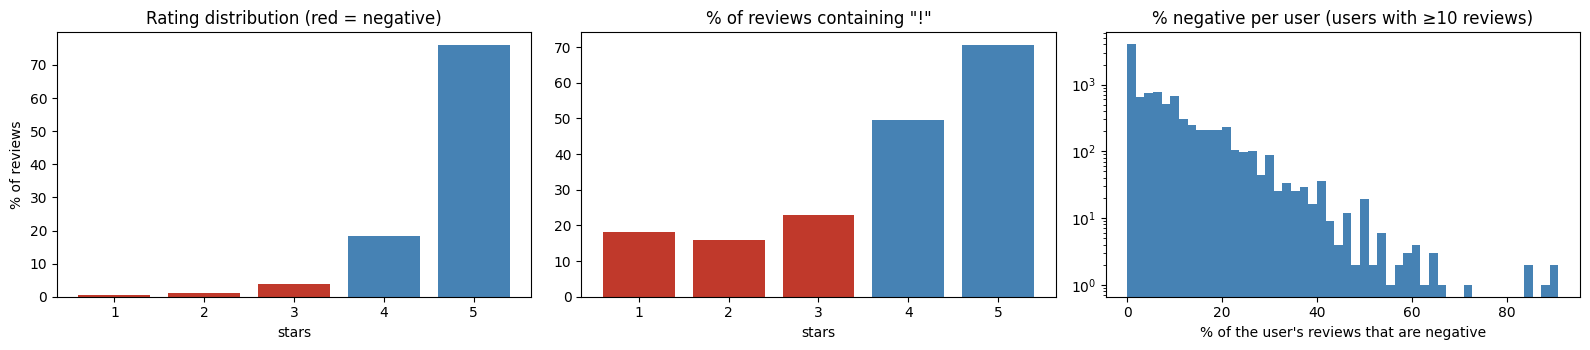

negative share: 5.5%  -> always predicting 'not negative' is 94.7% accurate
median review length by stars: {1: 41.0, 2: 44.0, 3: 49.0, 4: 48.0, 5: 46.0}
users with >=10 reviews: 39% never rate negatively, 8% rate >20% negatively


In [2]:
t2_nwords = t2_train.review.str.split().str.len()
t2_excl = t2_train.review.str.contains("!", regex=False)
t2_u = t2_train.groupby("user_id").y.agg(["mean", "size"]).query("size >= 10")

fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
colors = ["#c0392b"] * 3 + ["steelblue"] * 2
vc = t2_train.rating.value_counts().sort_index()
ax[0].bar(vc.index, vc.values / len(t2_train) * 100, color=colors)
ax[0].set_title("Rating distribution (red = negative)"); ax[0].set_xlabel("stars"); ax[0].set_ylabel("% of reviews")
ex = t2_excl.groupby(t2_train.rating).mean() * 100
ax[1].bar(ex.index, ex.values, color=colors)
ax[1].set_title('% of reviews containing "!"'); ax[1].set_xlabel("stars")
ax[2].hist(t2_u["mean"] * 100, bins=50, color="steelblue"); ax[2].set_yscale("log")
ax[2].set_title("% negative per user (users with ≥10 reviews)"); ax[2].set_xlabel("% of the user's reviews that are negative")
plt.tight_layout(); plt.show()

print(f"negative share: {100*t2_train.y.mean():.1f}%  -> always predicting 'not negative' is {100*(1-t2_test.y.mean()):.1f}% accurate")
print("median review length by stars:", t2_nwords.groupby(t2_train.rating).median().to_dict())
print(f"users with >=10 reviews: {100*(t2_u['mean']==0).mean():.0f}% never rate negatively, {100*(t2_u['mean']>0.2).mean():.0f}% rate >20% negatively")

* Strong **class imbalance** (5.5% negative), so accuracy is useless.
* Users differ a lot → a **per-user negativity prior** should be informative (the classification analogue of the user bias $\beta_u$).
* Length barely differs by rating, but "!" is much more common in positive reviews.

### 2.2 Evaluation protocol
* **AP** (area under precision–recall; random = prevalence ≈ 0.053) is the main metric because it focuses on the rare class. We also report **ROC-AUC** and **Precision@1000** (the top 1,000 reviews a moderator would read).
* **BER** and **F1** at a decision threshold, with the threshold chosen on **validation**.
* All hyperparameters are tuned on validation, and the test set is used once.
* **Baselines:** constant predictor, user prior only, recipe prior only, and review length + "!" only.

In [3]:
def t2_metrics(y, s, t_f1, t_ber, k=1000):
    yhat = s >= t_f1
    prec = (yhat & (y == 1)).sum() / max(yhat.sum(), 1); rec = (yhat & (y == 1)).sum() / y.sum()
    yb = s >= t_ber
    ber = 0.5 * ((yb & (y == 0)).sum() / (y == 0).sum() + (~yb & (y == 1)).sum() / y.sum())
    return {"AUC": roc_auc_score(y, s), "AP": average_precision_score(y, s),
            f"P@{k}": y[np.argsort(-s, kind="stable")[:k]].mean(), "BER": ber,
            "F1": 2 * prec * rec / max(prec + rec, 1e-12)}

T2_RESULTS, T2_SCORES = [], {}
t2_ytr, t2_yva, t2_yte = t2_train.y.values, t2_valid.y.values, t2_test.y.values

def t2_report(name, setting, s_va, s_te):
    # thresholds are fixed on validation, then applied to test
    p, r, t = precision_recall_curve(t2_yva, s_va)
    t_f1 = t[np.argmax((2 * p * r / np.maximum(p + r, 1e-12))[:-1])]
    fpr, tpr, tr_ = roc_curve(t2_yva, s_va)
    t_ber = tr_[np.argmin(fpr + 1 - tpr)]
    m = t2_metrics(t2_yte, s_te, t_f1, t_ber)
    T2_RESULTS.append({"setting": setting, "model": name, "val AP": average_precision_score(t2_yva, s_va), **m})
    T2_SCORES[name] = (s_va, s_te)
    print(f"{name:42s} test AUC {m['AUC']:.3f} | AP {m['AP']:.3f} | F1 {m['F1']:.3f}")

def t2_fit_lr(Xtr, Xva, Cs, **kw):
    # balanced class weights + C chosen by validation AP
    best = None
    for C in Cs:
        m = LogisticRegression(C=C, class_weight="balanced", max_iter=2000, **kw).fit(Xtr, t2_ytr)
        ap = average_precision_score(t2_yva, m.decision_function(Xva))
        if best is None or ap > best[0]: best = (ap, C, m)
    print(f"  best C = {best[1]} (val AP {best[0]:.3f})")
    return best[2]

### 2.3 Setting A: no review text

**Features (79):**
* **User prior:** smoothed negative rate $\frac{\#neg_u+\alpha\bar p}{n_u+\alpha}$, smoothed mean rating, $\log(1+n_u)$, and an unseen-user flag.
* **Recipe prior:** the same four features per recipe (13% of test recipes are cold-start).
* **Recipe content:** log minutes, steps, #ingredients, 7 nutrition values, and the 60 most common tags.
* **Year.**

To avoid **label leakage**, the priors for training rows are computed *leave-one-out*, i.e. without the row's own rating.

In [4]:
T2_ALPHA, t2_p0, t2_mu0 = 5.0, t2_train.y.mean(), t2_train.rating.mean()

def t2_prior(df, key, prefix, is_train):
    g = t2_train.groupby(key).agg(n=("y", "size"), neg=("y", "sum"), rsum=("rating", "sum"))
    m = g.reindex(df[key].values)
    n, neg, rsum = (m[c].fillna(0).values for c in ("n", "neg", "rsum"))
    if is_train:                                         # leave-one-out
        n, neg, rsum = n - 1, neg - df.y.values, rsum - df.rating.values
    return pd.DataFrame({f"{prefix}_neg_rate": (neg + T2_ALPHA * t2_p0) / (n + T2_ALPHA),
                         f"{prefix}_mean_rating": (rsum + T2_ALPHA * t2_mu0) / (n + T2_ALPHA),
                         f"{prefix}_log_n": np.log1p(n), f"{prefix}_unseen": (n == 0).astype(float)})

# recipe content features (one row per recipe)
t2_rec = t2_recipes[t2_recipes.id.isin(np.concatenate([d.recipe_id.unique() for d in (t2_train, t2_valid, t2_test)]))]
t2_tags = t2_rec.tags.apply(ast.literal_eval)
t2_nut = np.array(t2_rec.nutrition.apply(ast.literal_eval).tolist())
t2_generic = {"time-to-make", "course", "preparation", "main-ingredient", "dietary", "occasion",
           "cuisine", "equipment", "number-of-servings"}
t2_top_tags = [t for t, _ in Counter(t for ts in t2_tags for t in ts).most_common(80) if t not in t2_generic][:60]
t2_rec_feat = pd.DataFrame({"log_minutes": np.log1p(t2_rec.minutes.values), "n_steps": t2_rec.n_steps.values,
                            "n_ingredients": t2_rec.n_ingredients.values}, index=t2_rec.id.values)
for j, nm in enumerate(["calories", "total_fat", "sugar", "sodium", "protein", "sat_fat", "carbs"]):
    t2_rec_feat["log_" + nm] = np.log1p(np.clip(t2_nut[:, j], 0, None))
t2_tagsets = t2_tags.apply(set).values
for t in t2_top_tags:
    t2_rec_feat["tag_" + t] = [float(t in s) for s in t2_tagsets]

def t2_build_A(df, is_train):
    X = pd.concat([t2_prior(df, "user_id", "user", is_train), t2_prior(df, "recipe_id", "recipe", is_train),
                   t2_rec_feat.reindex(df.recipe_id.values).reset_index(drop=True)], axis=1)
    X["year"] = df.year.values
    return X.fillna(0)

t2_XA = {s: t2_build_A(d, s == "tr") for s, d in [("tr", t2_train), ("va", t2_valid), ("te", t2_test)]}
t2_scA = StandardScaler().fit(t2_XA["tr"].values)
t2_ZA = {s: t2_scA.transform(X.values) for s, X in t2_XA.items()}
print("Setting A feature matrix:", t2_XA["tr"].shape)

Setting A feature matrix: (631414, 79)


In [5]:
t2_report("Constant (always 'not negative')", "A", np.zeros(len(t2_valid)), np.zeros(len(t2_test)))
t2_report("User negative-rate prior", "A", t2_XA["va"].user_neg_rate.values, t2_XA["te"].user_neg_rate.values)
t2_report("Recipe negative-rate prior", "A", t2_XA["va"].recipe_neg_rate.values, t2_XA["te"].recipe_neg_rate.values)
t2_lrA = t2_fit_lr(t2_ZA["tr"], t2_ZA["va"], [0.01, 1.0])
t2_report("Logistic regression (all 79 features)", "A", t2_lrA.decision_function(t2_ZA["va"]), t2_lrA.decision_function(t2_ZA["te"]))

Constant (always 'not negative')           test AUC 0.500 | AP 0.053 | F1 0.101
User negative-rate prior                   test AUC 0.771 | AP 0.181 | F1 0.249
Recipe negative-rate prior                 test AUC 0.607 | AP 0.079 | F1 0.130


  best C = 1.0 (val AP 0.205)
Logistic regression (all 79 features)      test AUC 0.794 | AP 0.200 | F1 0.266


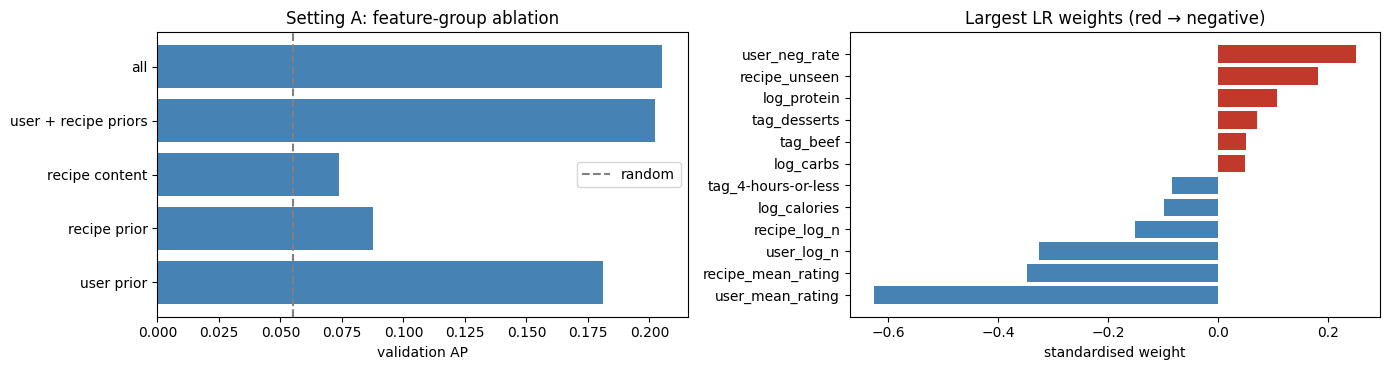

In [6]:
# Ablation: which feature group carries the signal? (validation AP)
t2_cols = t2_XA["tr"].columns
t2_groups = {"user prior": t2_cols.str.startswith("user_"), "recipe prior": t2_cols.str.startswith("recipe_"),
          "recipe content": ~t2_cols.str.startswith(("user_", "recipe_")) & (t2_cols != "year")}
t2_groups["user + recipe priors"] = t2_groups["user prior"] | t2_groups["recipe prior"]
t2_groups["all"] = np.ones(len(t2_cols), bool)
t2_abl = {g: average_precision_score(t2_yva, LogisticRegression(C=t2_lrA.C, class_weight="balanced", max_iter=2000)
                                  .fit(t2_ZA["tr"][:, m], t2_ytr).decision_function(t2_ZA["va"][:, m]))
       for g, m in t2_groups.items()}

t2_coef = pd.Series(t2_lrA.coef_[0], index=t2_cols).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].barh(list(t2_abl), list(t2_abl.values()), color="steelblue"); ax[0].axvline(t2_yva.mean(), ls="--", c="grey", label="random")
ax[0].set_xlabel("validation AP"); ax[0].set_title("Setting A: feature-group ablation"); ax[0].legend()
t2_top = pd.concat([t2_coef.head(6), t2_coef.tail(6)])
ax[1].barh(t2_top.index, t2_top.values, color=["steelblue"] * 6 + ["#c0392b"] * 6)
ax[1].set_title("Largest LR weights (red → negative)"); ax[1].set_xlabel("standardised weight")
plt.tight_layout(); plt.show()

Most of the signal comes from **who the user is**. Recipe content adds almost nothing on top of the user and recipe priors.

### 2.4 Setting B: review text

Bag-of-words models from the text-mining lectures, all followed by class-balanced logistic regression unless noted:
1. **Length + "!" count** (non-lexical baseline)
2. **Bag of words, top 1,000 unigrams** (lecture version)
3. **Naive Bayes** on unigram + bigram counts
4. **TF-IDF unigrams + bigrams**, which captures negation such as "not good" and "didn like"
5. **TF-IDF + Setting A features**, which combines what was written with who wrote it

Pre-processing is lower-casing and removing `<br/>`. We use **no stop-word removal** ("not", "no" and "but" are key words here) and **no stemming**. Words that appear in fewer than 5 reviews are dropped.

In [7]:
t2_txt = {s: d.review.str.replace(r"<br\s*/?>", " ", regex=True).str.lower()
          for s, d in [("tr", t2_train), ("va", t2_valid), ("te", t2_test)]}

# (1) length + "!" baseline
t2_L = {s: np.c_[np.log1p(t.str.split().str.len().values), t.str.count("!").values] for s, t in t2_txt.items()}
t2_m = LogisticRegression(class_weight="balanced").fit(t2_L["tr"], t2_ytr)
t2_report('Review length + "!" count', "B", t2_m.decision_function(t2_L["va"]), t2_m.decision_function(t2_L["te"]))

# (2) bag of words, top-1000 unigrams
t2_bow = CountVectorizer(max_features=1000).fit(t2_txt["tr"])
t2_B = {s: t2_bow.transform(t) for s, t in t2_txt.items()}
t2_m = t2_fit_lr(t2_B["tr"], t2_B["va"], [0.1, 1.0], solver="liblinear")
t2_report("BoW top-1000 unigrams + LR", "B", t2_m.decision_function(t2_B["va"]), t2_m.decision_function(t2_B["te"]))

# (3) Naive Bayes on uni+bigram counts
t2_cnt = CountVectorizer(ngram_range=(1, 2), min_df=5, max_features=200_000).fit(t2_txt["tr"])
t2_C = {s: t2_cnt.transform(t) for s, t in t2_txt.items()}
t2_nb = MultinomialNB(alpha=0.1).fit(t2_C["tr"], t2_ytr)                       # alpha=0.1 chosen on validation from {0.1, 0.5, 1}
t2_nb_s = lambda X: t2_nb.predict_log_proba(X)[:, 1] - t2_nb.predict_log_proba(X)[:, 0]
t2_report("Naive Bayes (uni+bigrams)", "B", t2_nb_s(t2_C["va"]), t2_nb_s(t2_C["te"]))

Review length + "!" count                  test AUC 0.763 | AP 0.123 | F1 0.204


  best C = 1.0 (val AP 0.628)
BoW top-1000 unigrams + LR                 test AUC 0.952 | AP 0.623 | F1 0.605


Naive Bayes (uni+bigrams)                  test AUC 0.953 | AP 0.649 | F1 0.640


In [8]:
# (4) TF-IDF uni+bigrams + LR
t2_tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=200_000, sublinear_tf=True).fit(t2_txt["tr"])
t2_T = {s: t2_tfidf.transform(t) for s, t in t2_txt.items()}
t2_lrT = t2_fit_lr(t2_T["tr"], t2_T["va"], [0.5, 2.0, 8.0], solver="liblinear")
t2_report("TF-IDF uni+bigrams + LR", "B", t2_lrT.decision_function(t2_T["va"]), t2_lrT.decision_function(t2_T["te"]))

# (5) TF-IDF + Setting A features (standardised, scaled by 0.1 to match TF-IDF magnitudes)
t2_H = {s: sp.hstack([t2_T[s], sp.csr_matrix(0.1 * t2_ZA[s])]).tocsr() for s in t2_T}
t2_lrH = LogisticRegression(C=t2_lrT.C, class_weight="balanced", solver="liblinear", max_iter=2000).fit(t2_H["tr"], t2_ytr)
t2_report("TF-IDF + user/recipe features + LR", "B", t2_lrH.decision_function(t2_H["va"]), t2_lrH.decision_function(t2_H["te"]))

  best C = 2.0 (val AP 0.762)
TF-IDF uni+bigrams + LR                    test AUC 0.970 | AP 0.760 | F1 0.699


TF-IDF + user/recipe features + LR         test AUC 0.975 | AP 0.784 | F1 0.718


### 2.5 Results (test set)

In [9]:
pd.DataFrame(T2_RESULTS).set_index(["setting", "model"]).round(3)

val AP    AUC     AP  P@1000  \
setting model                                                                 
A       Constant (always 'not negative')        0.055  0.500  0.053   0.052   
        User negative-rate prior                0.180  0.771  0.181   0.328   
        Recipe negative-rate prior              0.083  0.607  0.079   0.155   
        Logistic regression (all 79 features)   0.205  0.794  0.200   0.356   
B       Review length + "!" count               0.122  0.763  0.123   0.157   
        BoW top-1000 unigrams + LR              0.628  0.952  0.623   0.825   
        Naive Bayes (uni+bigrams)               0.652  0.953  0.649   0.831   
        TF-IDF uni+bigrams + LR                 0.762  0.970  0.760   0.938   
        TF-IDF + user/recipe features + LR      0.787  0.975  0.784   0.956   

                                                 BER     F1  
setting model                                                
A       Constant (always 'not negative')       0.500  0.101  
        User negative-rate prior               0.297  0.249  
        Recipe negative-rate prior             0.413  0.130  
        Logistic regression (all 79 features)  0.286  0.266  
B       Review length + "!" count              0.273  0.204  
        BoW top-1000 unigrams + LR             0.113  0.605  
        Naive Bayes (uni+bigrams)              0.104  0.640  
        TF-IDF uni+bigrams + LR                0.089  0.699  
        TF-IDF + user/recipe features + LR     0.079  0.718

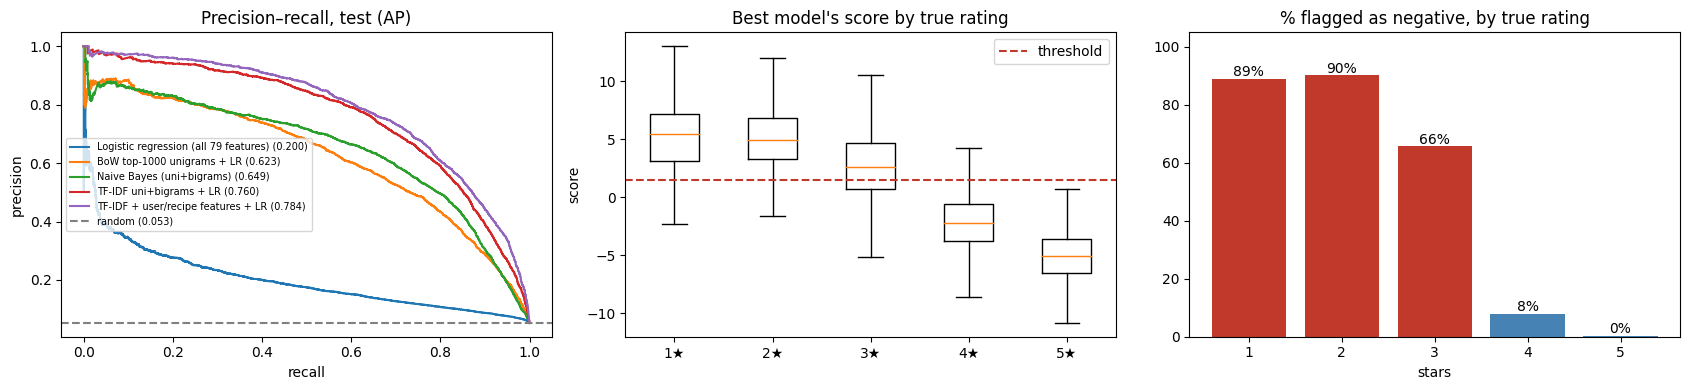

AUC for the stricter label (≤2★ vs 4-5★): 0.992


In [10]:
t2_best = "TF-IDF + user/recipe features + LR"
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for name in ["Logistic regression (all 79 features)", "BoW top-1000 unigrams + LR",
             "Naive Bayes (uni+bigrams)", "TF-IDF uni+bigrams + LR", t2_best]:
    s = T2_SCORES[name][1]; p, r, _ = precision_recall_curve(t2_yte, s)
    ax[0].plot(r, p, label=f"{name} ({average_precision_score(t2_yte, s):.3f})")
ax[0].axhline(t2_yte.mean(), ls="--", c="grey", label=f"random ({t2_yte.mean():.3f})")
ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision"); ax[0].set_title("Precision–recall, test (AP)"); ax[0].legend(fontsize=7)

# validity: score by true star rating, and share flagged at the validation-chosen F1 threshold
t2_sva, t2_ste = T2_SCORES[t2_best]
p, r, t = precision_recall_curve(t2_yva, t2_sva); t2_thr = t[np.argmax((2 * p * r / np.maximum(p + r, 1e-12))[:-1])]
t2_stars = t2_test.rating.values
ax[1].boxplot([t2_ste[t2_stars == k] for k in range(1, 6)], showfliers=False)
ax[1].set_xticks(range(1, 6)); ax[1].set_xticklabels([f"{k}★" for k in range(1, 6)])
ax[1].axhline(t2_thr, ls="--", c="#c0392b", label="threshold"); ax[1].legend()
ax[1].set_title("Best model's score by true rating"); ax[1].set_ylabel("score")
t2_flag = pd.Series(t2_ste >= t2_thr).groupby(t2_stars).mean() * 100
ax[2].bar(t2_flag.index, t2_flag.values, color=["#c0392b"] * 3 + ["steelblue"] * 2)
for k, v in t2_flag.items(): ax[2].text(k, v + 1, f"{v:.0f}%", ha="center")
ax[2].set_title("% flagged as negative, by true rating"); ax[2].set_xlabel("stars"); ax[2].set_ylim(0, 105)
plt.tight_layout(); plt.show()

t2_strict = (t2_stars <= 2).astype(int); t2_keep = t2_stars != 3
print(f"AUC for the stricter label (≤2★ vs 4-5★): {roc_auc_score(t2_strict[t2_keep], t2_ste[t2_keep]):.3f}")

In [11]:
t2_vocab = t2_tfidf.get_feature_names_out(); t2_o = np.argsort(t2_lrT.coef_[0])
print("most negative n-grams:", ", ".join(t2_vocab[t2_o[::-1][:20]]))
print("most positive n-grams:", ", ".join(t2_vocab[t2_o[:20]]))

pd.set_option("display.max_colwidth", 200)
t2_err = t2_test[["rating", "review"]].assign(score=t2_ste)
t2_short = t2_err.review.str.split().str.len() < 30
print("\nMissed negatives (3★ with positive text):")
display(t2_err[(t2_stars <= 3) & (t2_ste < t2_thr) & t2_short].nsmallest(3, "score"))
print("False alarms (4★ that read negative):")
display(t2_err[(t2_stars >= 4) & (t2_ste >= t2_thr) & t2_short].nlargest(3, "score"))

most negative n-grams: sorry, bland, ok, three stars, okay, not, potential, just didn, thanks anyway, was okay, disappointed, didn like, very bland, definitly, just ok, unfortunately, wasn, disappointing, lacked, horrible
most positive n-grams: delicious, wonderful, great, thanks, perfect, fantastic, excellent, keeper, yummy, awesome, loved, very good, so good, fabulous, great recipe, amazing, used, thanx, yum, really good



Missed negatives (3★ with positive text):


,rating,review,score
57262,3,Thanks.,-11.469224
48431,3,Wonderful! This is a real keeper. Thanks for posting.,-11.182814
28852,3,Yummy! And easy.,-7.592591


False alarms (4★ that read negative):


,rating,review,score
2311,4,ok,10.845907
36897,4,"These were not difficult to put together, and the flavor was ok. They were just not for us. I used mozzarella cheese.",10.260424
25100,4,I liked the chicken but my DH said that it was just okay.,8.892308


### 2.6 Discussion

* **Without text the task is hard.** The best no-text model (LR) reaches AUC 0.79 and AP 0.20, about 4× random. Nearly all of the signal is the **user prior**; recipe content adds almost nothing.
* **Text makes it easy.** Moving from BoW (AP 0.62) to Naive Bayes (0.65) to **TF-IDF + bigrams (0.76)**, the bigrams capture hedging and negation ("was okay", "just ok", "didn like", "no flavor"). Naive Bayes double-counts correlated n-grams, so it trails LR.
* **Best model: TF-IDF + user/recipe features**, with AUC 0.975, AP 0.784, P@1000 0.956 and F1 0.72. The same words mean more coming from a critical user.
* **Remaining errors are label ambiguity at 3★/4★.** Some 3★ reviews read fully positive and some 4★ reviews say "just okay". For ≤2★ vs 4–5★ the AUC is 0.99.
* **Trade-offs:** linear bag-of-words models are fast (minutes on 630k reviews) and interpretable. Setting A works before a review exists, so it can feed the recommender (Task 4), but it is much weaker.

### 2.7 Related work
* Majumder et al., EMNLP 2019 introduced this Food.com dataset, using reviews as preference signals for recipe generation.
* Pang, Lee & Vaithyanathan, EMNLP 2002 compared NB, MaxEnt (LR) and SVM sentiment classifiers on n-grams; discriminative models beat NB, as here.
* Wang & Manning, ACL 2012 showed that bigrams consistently help sentiment classification.
* McAuley & Leskovec, RecSys 2013 combined review text with user/item rating biases, the same idea as our best model.